In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.stats import pearsonr, spearmanr

data = {
    "Responden"          : ["R1", "R2", "R3", "R4", "R5", "R6", "R7", "R8", "R9", "R10"],
    "Pendapatan_Juta_Rp" : [12.0, 6.5, 9.0, 15.5, 4.0, 10.5, 7.8, 17.0, 11.2, 5.2],
    "Usia_Tahun"         : [28, 41, 35, 135, 22, 39, 30, 49, 37, 26],
    "Skor_Kepuasan"      : [80, 55, np.nan, 88, 35, 78, 115, 90, 82, 48],  # nilai kosong juga biisi dgn 'None'
    "Suhu_C"             : [24, 30, 26, 23, 33, 25, 28, 22, 24, 31],
    "Pendidikan"         : [3, 2, 3, 4, 1, 3, 2, 4, 3, 1]
}

df = pd.DataFrame(data)
df

,Responden,Pendapatan_Juta_Rp,Usia_Tahun,Skor_Kepuasan,Suhu_C,Pendidikan
0,R1,12.0,28,80.0,24,3
1,R2,6.5,41,55.0,30,2
2,R3,9.0,35,NaN,26,3
3,R4,15.5,135,88.0,23,4
4,R5,4.0,22,35.0,33,1
5,R6,10.5,39,78.0,25,3
6,R7,7.8,30,115.0,28,2
7,R8,17.0,49,90.0,22,4
8,R9,11.2,37,82.0,24,3
9,R10,5.2,26,48.0,31,1


In [3]:
df.head(5)

,Responden,Pendapatan_Juta_Rp,Usia_Tahun,Skor_Kepuasan,Suhu_C,Pendidikan
0,R1,12.0,28,80.0,24,3
1,R2,6.5,41,55.0,30,2
2,R3,9.0,35,NaN,26,3
3,R4,15.5,135,88.0,23,4
4,R5,4.0,22,35.0,33,1


In [4]:
df.shape

(10, 6)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Responden           10 non-null     str    
 1   Pendapatan_Juta_Rp  10 non-null     float64
 2   Usia_Tahun          10 non-null     int64  
 3   Skor_Kepuasan       9 non-null      float64
 4   Suhu_C              10 non-null     int64  
 5   Pendidikan          10 non-null     int64  
dtypes: float64(2), int64(3), str(1)
memory usage: 612.0 bytes


In [6]:
df.isnull().sum()

Responden             0
Pendapatan_Juta_Rp    0
Usia_Tahun            0
Skor_Kepuasan         1
Suhu_C                0
Pendidikan            0
dtype: int64

In [10]:
df.describe()

,Pendapatan_Juta_Rp,Usia_Tahun,Skor_Kepuasan,Suhu_C,Pendidikan
count,10.000000,10.000000,9.000000,10.000000,10.000000
mean,9.870000,44.200000,74.555556,26.600000,2.600000
std,4.241344,32.879578,24.505668,3.717825,1.074968
min,4.000000,22.000000,35.000000,22.000000,1.000000
25%,6.825000,28.500000,55.000000,24.000000,2.000000
50%,9.750000,36.000000,80.000000,25.500000,3.000000
75%,11.800000,40.500000,88.000000,29.500000,3.000000
max,17.000000,135.000000,115.000000,33.000000,4.000000


In [16]:
def clean_data(frame) :

    invalid_reasons = {}
    allowed_level = {1, 2, 3, 4}
    duplicated_idx = frame["Responden"].duplicated(keep=False)
    for position, (index, row) in enumerate(frame.iterrows()) :
        reason = []

        if pd.isna(row["Responden"]) or not str(row["Responden"]).strip() :
            reason.append("Responden kosong")
        elif duplicated_idx.iloc[position] :
            reason.append(" ID Responden terduplikasi")

        numeric_columns = ["Pendapatan_Juta_Rp", "Usia_Tahun", "Skor_Kepuasan", "Suhu_C"]

        if pd.notna(row["Pendapatan_Juta_Rp"]) and row["Pendapatan_Juta_Rp"] <= 0 :
            reason.append("Pendapatan tidak boleh kurang dari nol")

        if pd.notna(row["Usia_Tahun"]) and not 18 <= row["Usia_Tahun"] <= 120 :
            reason.append("Usia tidak boleh kurang dari 18 tahun dan tidak boleh lebih dari 120 tahun")

        if pd.notna(row["Skor_Kepuasan"]) and not 0 <= row["Skor_Kepuasan"] <= 100 :
            reason.append("Skor Kepuasan tidak boleh kurang dari 0 dan tidak boleh lebih dari 100")

        if pd.notna(row["Suhu_C"]) and not -50 <= row["Suhu_C"] <= 60 :
            reason.append("Suhu harus direntang antara -50 hingga 60 derajat Celcius")

        if pd.notna(row["Pendidikan"]) and row["Pendidikan"] not in allowed_level :
            reason.append("Pendidikan harus ada pada rentang 1 sampai 4")

        if reason :
            invalid_reasons[index] = "; ".join(reason)

    invalid = frame.loc[list(invalid_reasons)].copy()
    invalid["Alasan_Tidak_Valid"]=[
        invalid_reasons[index] for index in invalid.index
    ]
    valid = frame.drop(index=list(invalid_reasons)).copy()
    return valid, invalid

valid_df, invalid_df = clean_data(df)
print("hasil validasi")
print(f"jumlah data awal : {len(df)}")
print(f"jumlah data tidak valid : {len(invalid_df)}")
print(f"jumlah data valid : {len(valid_df)}")
print("alasannya : ")
if invalid_df.empty :
    print("data bersih")
else :
    print(invalid_df[["Responden", "Alasan_Tidak_Valid"]].to_string(index = False))

hasil validasi
jumlah data awal : 10
jumlah data tidak valid : 2
jumlah data valid : 8
alasannya : 
Responden                                                         Alasan_Tidak_Valid
       R4 Usia tidak boleh kurang dari 18 tahun dan tidak boleh lebih dari 120 tahun
       R7     Skor Kepuasan tidak boleh kurang dari 0 dan tidak boleh lebih dari 100


In [17]:
df.columns

Index(['Responden', 'Pendapatan_Juta_Rp', 'Usia_Tahun', 'Skor_Kepuasan',
       'Suhu_C', 'Pendidikan'],
      dtype='str')

In [ ]:
iqr_variabel = "Skor_Kepuasan"
q1 = valid_df[iqr_variabel].quantile(0.25)
q3 = valid_df[iqr_variabel].quantile(0.75)

iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr 

iqr_outlier = valid_df.loc[
    (valid_df[iqr_variabel] < lower_bound) | (valid_df[iqr_variabel] > upper_bound),  # | ini buat or tpi bergantung sma datanya, kalo or itu dipake buat true false aja, & ini buat and
    ["Responden", iqr_variabel]
]

print(f"outlier pada q1 : {q1:.2f}")
print(f"outlier pada q3 : {q3:.2f}")
print(f"IQR             : {iqr:.2f}")
print(f"batas bawah     : {lower_bound:.2f}")
print(f"batas atas      : {upper_bound:.2f}")

if iqr_outlier.empty :
    print("outlier tidak ada")

else :
    print("ID outliers")
    print(iqr_outlier.to_string(index=False)) # outlier iqr hanya ditandai dan tidak otomatis dihapus dari data valid


outlier pada q1 : 51.50
outlier pada q3 : 81.00
IQR             : 29.50
batas bawah     : 7.25
batas atas      : 125.25
outlier tidak ada


In [21]:
df.columns

Index(['Responden', 'Pendapatan_Juta_Rp', 'Usia_Tahun', 'Skor_Kepuasan',
       'Suhu_C', 'Pendidikan'],
      dtype='str')

In [26]:
x = valid_df["Pendapatan_Juta_Rp"]
y = valid_df["Usia_Tahun"]
corr, p_val = pearsonr(x, y) 
r_squared = corr**2
absolute_correlation = abs(corr)

if absolute_correlation < 0.20 :
    strength = "super weak"

elif absolute_correlation < 0.40 :
    strength = "weak"

elif absolute_correlation < 0.60 :
    strength = "sedang"

elif absolute_correlation < 0.80 :
    strength = "strong"

else :
    strength = "very strong"

direction = "positive" if corr > 0 else "negative"

print(f"koefisien relasi (r) : {corr:.4f}")
print(f"arah hubungan        : {direction}")
print(f"strength             : {strength}")

koefisien relasi (r) : 0.7147
arah hubungan        : positive
strength             : strong


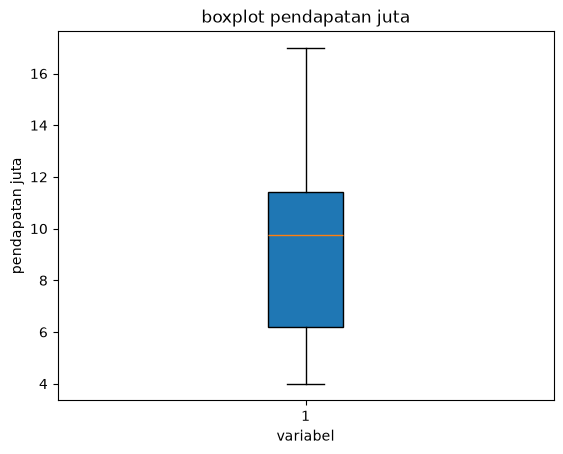

In [38]:
plt.Figure(figsize=(8,5))
plt.boxplot(valid_df["Pendapatan_Juta_Rp"], patch_artist=True)
plt.title("boxplot pendapatan juta")
plt.ylabel("pendapatan juta")
plt.xlabel("variabel")
plt.show()

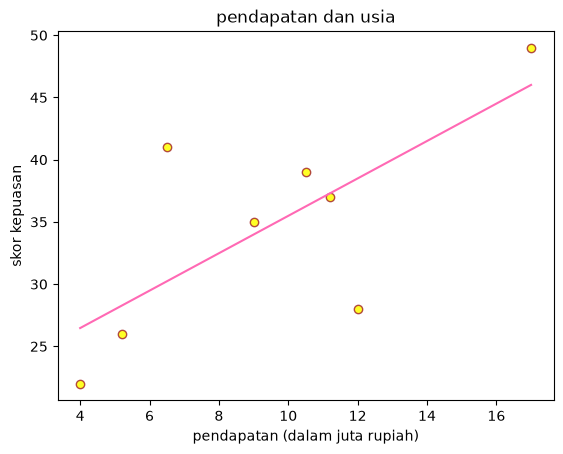

In [36]:
plt.Figure(figsize=(8,5))
plt.scatter(x,y, color="yellow", alpha = 0.85, edgecolors="brown")
trend_X = np.linspace(x.min(), x.max(), 100)
trend_Y = np.polyval(np.polyfit(x, y, 1), trend_X)
plt.plot(trend_X, trend_Y, color="hotpink", label="garis tren linear")
plt.title("pendapatan dan usia")
plt.xlabel("pendapatan (dalam juta rupiah)")
plt.ylabel("skor kepuasan")
plt.show()